In [ ]:
import numpy as np
import random
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [11]:
# =============================================================================
# RULES AND STATE CONVENTIONS
# =============================================================================
# State: (a1, a2, b1, b2, turn)
#   a1, a2 = Player 1 left and right hand (0 = dead)
#   b1, b2 = Player 2 left and right hand (0 = dead)
#   turn   = 1 (Player 1 to move) or 2 (Player 2 to move)
#
# Attack: new_val = (target + attacker) % 5
#   If new_val == 0 the hand dies (this covers the exactly-5 case).
#   e.g. 3 + 2 = 5 → 0 (dead); 3 + 4 = 7 → 2 (rolls over, survives)
# No splits allowed.
# A player with both hands == 0 loses immediately.
# =============================================================================

def attack(state, atk_idx, tgt_idx):
    """
    Finds next state after an attack

    Parameters
    ----------
    state   : (a1, a2, b1, b2, turn)
    atk_idx : 0 or 1 — which of the current player's hands attacks
    tgt_idx : 0 or 1 — which of the opponent's hands is targeted

    Returns
    -------
    New state tuple, or None if the action is illegal.
    """
    a1, a2, b1, b2, turn = state
    if turn == 1:
        player_hands, opp_hands = [a1,a2], [b1,b2]
    else:
        player_hands, opp_hands = [b1,b2], [a1,a2]

    # Dont play with dead hand
    if player_hands[atk_idx] == 0 or opp_hands[tgt_idx] == 0:
        return None

    opp_next = list(opp_hands)
    opp_next[tgt_idx] = (opp_hands[tgt_idx] + player_hands[atk_idx]) % 5

    if turn == 1:
        return (a1, a2, opp_next[0], opp_next[1], 2)
    else:
        return (opp_next[0], opp_next[1], b1, b2, 1)


def get_legal_actions(state):
    """
    Return all legal (atk_idx, tgt_idx) attack pairs from a state.
    Returns a list of (atk_idx, tgt_idx) tuples.
    """
    a1, a2, b1, b2, turn = state
    if turn == 1:
        player_hands, opp_hands = [a1,a2], [b1,b2]
    elif turn == 2:
        player_hands, opp_hands = [b1,b2], [a1,a2]

    actions = []
    for atk in range(2):
        for tgt in range(2):
            if player_hands[atk] != 0 and opp_hands[tgt] != 0:
                actions.append((atk, tgt))
    return actions


def is_terminal(state):
    """
    Returns (True, winner) if terminal, else (False, None).
    winner = 0 → Player 1 wins, 1 → Player 2 wins.
    """
    a1, a2, b1, b2, _ = state
    if a1 == 0 and a2 == 0:
        return True, 2   # P1 dead → P2 wins
    if b1 == 0 and b2 == 0:
        return True, 1   # P2 dead → P1 wins
    return False, None



In [12]:
def find_all_reachable_states(start_state=(1, 1, 1, 1, 1)):
    """
    BFS from start_state.

    Returns
    -------
    reachable   : set of state tuples
    transitions : dict  state -> list of ((atk, tgt), next_state)
    """
    reachable   = set()
    transitions = defaultdict(list)
    stack = [start_state]

    while stack:
        state = stack.pop()
        if state in reachable:
            continue
        reachable.add(state)

        terminal, _ = is_terminal(state)
        if terminal:
            continue

        for action in get_legal_actions(state):
            next_state = attack(state, *action)
            if next_state is not None:
                transitions[state].append((action, next_state))
                if next_state not in reachable:
                    stack.append(next_state)

    return reachable, transitions


In [13]:
def compute_minimax_values(reachable, transitions):
    """
    Values:
        +1 = P1 can force a win
        -1 = P2 can force a win
         0 = draw (neither can force a win)
    """

    values = {}
    for s in reachable:
        terminal, winner = is_terminal(s)
        if terminal:
            values[s] = 1 if winner == 1 else -1
        else:
            values[s] = None    # unknown for now

    # Backward induction
    # This code checks if the next state is a win (in which case the player will pick it)
    # or if all next states are losses/draws this state is a draw.
    # because we start from terminal states this will work in reverse topological order
    # and will leave all "unchanged" value as values which cannot be forced win or draw
    changed = True
    while changed:
        changed = False

        for s in reachable:
            if s == (1,4,0,3,2):
                pass
            if values[s] is not None:
                continue  # already decided

            *_, turn = s
            children = transitions.get(s, [])
            child_vals = [values[ns] for _, ns in children]

            # No moves → draw
            if not child_vals:
                values[s] = 0
                changed = True
                print("There are no moves somehow")
                continue

            #maximise
            if turn == 1:
                # If any known child is a P1 win then this is a p1 win
                if any(v == 1 for v in child_vals):
                    values[s] = 1
                    changed = True
                    continue

                # If all children are known, maximum will be p2 win or draw.
                if all(v is not None for v in child_vals):
                    values[s] = max(child_vals)
                    changed = True
                    continue

            #minimise
            else:
                # if any known child is a P2 win then this state is p2 win
                if any(v == -1 for v in child_vals):
                    values[s] = -1
                    changed = True
                    continue
                # if all children are known then maximum will be p1 win or draw
                if all(v is not None for v in child_vals):
                    values[s] = min(child_vals)
                    changed = True
                    continue

    # unknown is draw
    for s in reachable:
        if values[s] is None:
            values[s] = 0

    return values

def compute_optimal_policy(reachable, transitions):
    """
    Uses minimax values to compute optimal actions.
    """
    values = compute_minimax_values(reachable, transitions)
    policy = {}

    for state in reachable:
        if state == (2, 4, 0, 1, 1):
            pass
        _, _, _, _, turn = state
        best_action = None
        best_val = -float('inf') if turn == 1 else float('inf')

        for action, next_state in transitions[state]:
            val = values[next_state]
            if (turn == 1 and val > best_val) or (turn == 2 and val < best_val):
                best_val = val
                best_action = action
            if turn == 1 and best_val == 1:
                break
            elif turn == 2 and best_val == -1:
                break
        policy[state] = best_action

    return values, policy


In [14]:

# =============================================================================
# Absorbing markov chain
# Each player follows an epsilon-greedy mixed strategy:
#   With probability (1 - epsilon): take the minimax optimal action.
#   With probability epsilon:       choose uniformly at random.
#
#
# Win probabilities and expected game lengths are computed analytically:
#   Q  = transient-to-transient sub-matrix of P
#   R  = transient-to-absorbing  sub-matrix of P
#   N  = (I - Q)^{-1}                  fundamental matrix
#   B  = N @ R                          absorption probabilities
#   t  = N @ 1                          expected steps to absorption
# =============================================================================
import networkx as nx


def find_policy_absorbing_sccs(reachable, transitions, policy,p2_random = True):
    """
    Find SCCs (loops) in the policy graph, essentially draws which are forced because of players actions
    A player could leave this draw loop but that would result in their loss.
    each state has exactly one outgoing edge (the policy's chosen action).
    """

    Gp = nx.DiGraph()

    # Build policy graph: one edge per state
    for s in reachable:
        terminal, _ = is_terminal(s)
        if terminal:
            continue

        *_, turn = s
        edges = transitions.get(s, [])

        if turn == 1:
            # P1 always picks optimal
            a_star = policy.get(s)
            if a_star is None:
                continue
            for (a, ns) in edges:
                if a == a_star:
                    Gp.add_edge(s, ns)
                    break

        else:
            # P2 could randomely pick between all actions
            if p2_random == True:
                for (a, ns) in edges:
                    Gp.add_edge(s, ns)
            else:
                # or can pick the optimal action
                a_star = policy.get(s)
                if a_star is None:
                    continue
                for (a, ns) in edges:
                    if a == a_star:
                        Gp.add_edge(s, ns)
                        break
    # Find SCCs
    scc_list = list(nx.strongly_connected_components(Gp))
    policy_scc_states = set()

    for comp in scc_list:
        comp = list(comp)

        # Skip SCCs containing terminals
        if any(is_terminal(s)[0] for s in comp):
            continue

        # Check if SCC has outgoing edges to states outside the SCC
        outgoing = False
        for s in comp:
            for _, ns in Gp.out_edges(s):
                if ns not in comp:
                    outgoing = True
                    break
            if outgoing:
                break

        # Closed SCC in policy graph means a policy-driven SCC
        if not outgoing:
            policy_scc_states.update(comp)

    return policy_scc_states

def find_absorbing_draw_sccs(reachable, transitions):
    """
    Returns a set of states that belong to SCCs which:
    - have size > 1 (cycle)
    - contain no terminal states
    - have no outgoing edges to other SCCs
    These SCCs are treated as absorbing draw states.
    meaning nothing a player does can exit this loop
    example: (1, 0, 2, 0, 1)
    """
    # Build directed graph
    G = nx.DiGraph()
    for s in reachable:
        for _, ns in transitions.get(s, []):
            G.add_edge(s, ns)

    # Find SCCs
    scc_list = list(nx.strongly_connected_components(G))

    absorbing_draw_states = set()
    for comp in scc_list:

        # Check if SCC has outgoing edges
        outgoing = False
        for s in list(comp):
            for action in get_legal_actions(s):
                ns = attack(s, *action)
                if ns not in comp:
                    outgoing = True
                    break

        # If no outgoing edges → absorbing draw SCC
        if not outgoing and not any(is_terminal(state)[0] for state in comp):
            absorbing_draw_states.update(comp)
    return absorbing_draw_states

def build_transition_matrix(state_list, state_idx, transitions, policy, epsilon, p2_random):
    """
    Build the full (n x n) transition matrix P under epsilon-greedy play.
    """
    n = len(state_list)
    P = np.zeros((n, n))

    for state in state_list:
        i = state_idx[state]
        terminal, _ = is_terminal(state)
        if terminal:
            P[i, i] = 1.0
            continue
        a1, a2, b1, b2, turn = state
        action_list = transitions[state]   # [(action, next_state), ...]
        opt_action = policy.get(state)
        
        k = len(action_list)

        if turn == 1:
            # P1 always take the minimax-optimal action
            for action, next_state in action_list:
                j = state_idx[next_state]
                prob = epsilon / k
                if action == opt_action:
                    prob += (1.0 - epsilon)
                P[i, j] += prob
        else:
            if p2_random == True:
                # P2 choose uniformly at random
                for action, next_state in action_list:
                    j = state_idx[next_state]
                    P[i, j] += 1.0 / k
            else:
                
                for action, next_state in action_list:
                    j = state_idx[next_state]
                    prob = epsilon / k
                    if action == opt_action:
                        prob += (1.0 - epsilon)
                    P[i, j] += prob
    return P


def absorbing_markov_chain(reachable, transitions, policy, epsilon, p2_random = True):
    """
    Solve the absorbing Markov chain analytically.

    Returns
    -------
    win_probs  : dict  state -> P(Player 1 wins from this state)
    exp_length : dict  state -> expected steps to game end from this state
    """
    state_list = sorted(reachable)
    state_idx  = {s: i for i, s in enumerate(state_list)}

  
    P = build_transition_matrix(state_list, state_idx, transitions,
                                policy, epsilon, p2_random)
    if epsilon > 0:
        policy_cycles = []
    elif epsilon == 0 or p2_random == False:
        policy_cycles = find_policy_absorbing_sccs(reachable, transitions, policy,p2_random)
    absorbing_draw_states = find_absorbing_draw_sccs(reachable, transitions)  
    absorbing_states = [
        s for s in reachable
        if is_terminal(s)[0] or s in absorbing_draw_states or s in policy_cycles
    ]
    

    # Partition indices into transient and absorbing
    absorbing_idx = []
    transient_idx = []

    for state in state_list:
        i = state_idx[state]
        terminal, _ = is_terminal(state)

        if terminal or state in absorbing_draw_states or state in policy_cycles:
            absorbing_idx.append(i)
        else:
            transient_idx.append(i)

    print("Absorbing draw states:", len(absorbing_draw_states))
    print("Policy absorbing states:", len(policy_cycles))
    print("Transient states:", len(transient_idx))
    # Sub-matrices
    Q = P[np.ix_(transient_idx, transient_idx)]
    R = P[np.ix_(transient_idx, absorbing_idx)]
    
    # Fundamental matrix  N = (I - Q)^{-1}
    I = np.eye(len(transient_idx))
    try:
        N = np.linalg.inv(I - Q)
    except Exception as e:
        print("Error",e)
        return I, Q, None
    # Absorption probabilities  B = N R
    B = N @ R

    # Which absorbing states are Player 1 wins?
    absorbing_states = [state_list[i] for i in absorbing_idx]
    p1_win_cols = [
        k for k, s in enumerate(absorbing_states)
        if is_terminal(s)[1] == 1
    ]
    draw_cols = [
        k for k, s in enumerate(absorbing_states)
        if s in absorbing_draw_states
    ]

    win_probs  = {}
    draw_probs  = {}
    exp_length = {}

    for row, si in enumerate(transient_idx):
        state = state_list[si]
        win_probs[state]  = float(np.sum(B[row, p1_win_cols]))
        draw_probs[state]  = float(np.sum(B[row, draw_cols]))
        exp_length[state] = float(np.sum(N[row, :]))

    # Terminal states
    for state in state_list:
        terminal, winner = is_terminal(state)
        if terminal:
            win_probs[state]  = 1.0 if winner == 1 else 0.0
            exp_length[state] = 0.0
            draw_probs[state] = 0.0

    for state in absorbing_draw_states:
        win_probs[state] = 0.0
        draw_probs[state] = 1.0
        exp_length[state] = 0.0
    
    for state in policy_cycles:
        win_probs[state] = 0.0
        draw_probs[state] = 1.0
        exp_length[state] = 0.0

    return win_probs, exp_length, draw_probs




In [15]:


# =============================================================================
# Monte Carlo simulation
# Simulates many games under epsilon-greedy play to verify the analytical
# Markov chain results.
# =============================================================================
def simulate_game(start_state, transitions, policy, epsilon, absorbing_draw_states,
                  max_steps=5000, p2_random=True):

    state = start_state
    player = 1

    for steps in range(max_steps):

        # Absorbing draw SCC, these will naturally exceed max_steps,
        # but we return once they reach the draw state to find how many moves
        # to get to the draw state
        if state in absorbing_draw_states:
            return -1, steps

        # Terminal
        terminal, winner = is_terminal(state)
        if terminal:
            return winner, steps

        actions = transitions[state]
        opt_action = policy.get(state)

        
        if player == 1:
            if random.random() < epsilon or opt_action is None:
                _, next_state = random.choice(actions)
            else:
                next_state = next(ns for a, ns in actions if a == opt_action)
            player = 2


        else:
            if p2_random:
                # P2 random
                _, next_state = random.choice(actions)
            else:
                # P2 greedy-epsilon
                if random.random() < epsilon or opt_action is None:
                    _, next_state = random.choice(actions)
                else:
                    next_state = next(ns for a, ns in actions if a == opt_action)
            player = 1

        state = next_state

    return -1, max_steps



def monte_carlo_simulation(start_state, reachable, transitions, policy, epsilon,
                           n_sims=20000, p2_random = True):
    """
    Estimate P(Player 1 wins), draws and expected game length via simulation.
    """
    p1_wins = 0
    total_steps = 0
    draws = 0
    draw_states = find_absorbing_draw_sccs(reachable, transitions)  
    for _ in range(n_sims):
        winner, steps = simulate_game(start_state, transitions, policy, epsilon, draw_states, p2_random=p2_random)
        total_steps += steps
        if winner == 1:
            p1_wins += 1
        elif winner == -1:
            draws +=1 
    return p1_wins/n_sims, total_steps/n_sims, draws/n_sims 


In [16]:


#using cannonical states, this means equivalent states are mapped into the same node to avoid overcrowding
def canonical(state):
    """
    State is (a1, a2, b1, b2, turn)
    a1,a2 are interchangeable
    b1,b2 are interchangeable
    """
    # Uncomment to get non-canonical states
    # return state

    a1, a2, b1, b2, turn = state
    A = tuple(sorted((a1, a2)))
    B = tuple(sorted((b1, b2)))
    return (A[0], A[1], B[0], B[1], turn)


In [17]:
print("\n[2] STATE SPACE ENUMERATION (BFS)")

#FOR MARKER MODIFY THIS VARIABLE TO CHANGE FROM RANDOM TO E-GREEDY
P2_Random = True
start = (1, 1, 1, 1, 1)
reachable, transitions = find_all_reachable_states(start)
terminal_states  = [s for s in reachable if is_terminal(s)[0]]
transient_states = [s for s in reachable if not is_terminal(s)[0]]
p1_term = [s for s in terminal_states if is_terminal(s)[1] == 1]
p2_term = [s for s in terminal_states if is_terminal(s)[1] == 2]
absorbing_draws = find_absorbing_draw_sccs(reachable,transitions)
print(f"  Total reachable : {len(reachable)}")
print(f"  Transient       : {len(transient_states)}")
print(f"  Terminal        : {len(terminal_states)}"
        f"  (P1 wins: {len(p1_term)}, P2 wins: {len(p2_term)})")
print(f"  Forced draws    : {len(absorbing_draws)} ")
# Minimax
print("\n[3] Minimax")
values, policy = compute_optimal_policy(reachable, transitions)
sv = values[start]
print(f"  V(start) = {sv:+d}  →  "
        f"{'P1 forced win' if sv==1 else 'P2 forced win' if sv==-1 else 'draw'}")

p1_win_states = sum(1 for v in values.values() if v ==  1)
p2_win_states = sum(1 for v in values.values() if v == -1)
print(f"  States where P1 wins under optimal play : {p1_win_states}")
print(f"  States where P2 wins under optimal play : {p2_win_states}")

# Epsilon sweep 
print("\n[4] EPSILON SWEEP")
epsilons     = np.linspace(0, 1, 21)
amc_win, amc_p2, amc_len, amc_draw = [], [], [], []
mc_win,  mc_p2,  mc_len,  mc_draw  = [], [], [], []

for eps in epsilons:
    wp_dict, el_dict, dp_dict = absorbing_markov_chain(reachable, transitions, policy, eps, p2_random=P2_Random)

    p1w = wp_dict.get(start, np.nan)
    dr  = dp_dict.get(start, np.nan)
    p2w = 1 - p1w - dr

    amc_win.append(p1w)
    amc_draw.append(dr)
    amc_p2.append(p2w)
    amc_len.append(el_dict.get(start, np.nan))


    mw, ml, md = monte_carlo_simulation(
        start, reachable, transitions, policy, eps,
        n_sims=10000, p2_random=P2_Random
    )
    mc_win.append(mw)
    mc_draw.append(md)
    mc_p2.append(1 - mw - md)
    mc_len.append(ml)

    print(
        f"  ε={eps:.2f}  "
        f"AMC P1={amc_win[-1]:.4f}  AMC P2={amc_p2[-1]:.4f}  AMC draw={amc_draw[-1]:.4f}  "
        f"MC P1={mc_win[-1]:.4f}   MC P2={mc_p2[-1]:.4f}   MC draw={mc_draw[-1]:.4f}  "
        f"AMC len={amc_len[-1]:.2f}  MC len={mc_len[-1]:.2f}"
    )

amc_win  = np.array(amc_win)
amc_p2   = np.array(amc_p2)
amc_len  = np.array(amc_len)
amc_draw = np.array(amc_draw)

mc_win  = np.array(mc_win)
mc_p2   = np.array(mc_p2)
mc_len  = np.array(mc_len)
mc_draw = np.array(mc_draw)

# Win probability heatmap
eps_samples  = [0.0, 0.1, 0.5, 1.0]
heatmap_data = {}
for eps in eps_samples:
    wp, _, _ = absorbing_markov_chain(reachable, transitions, policy, eps, p2_random=P2_Random)
    heatmap_data[eps] = wp



[2] STATE SPACE ENUMERATION (BFS)
  Total reachable : 1163
  Transient       : 1115
  Terminal        : 48  (P1 wins: 24, P2 wins: 24)
  Forced draws    : 32 

[3] Minimax
  V(start) = +0  →  draw
  States where P1 wins under optimal play : 380
  States where P2 wins under optimal play : 380

[4] EPSILON SWEEP
Absorbing draw states: 32
Policy absorbing states: 32
Transient states: 1083
  ε=0.00  AMC P1=0.9286  AMC P2=0.0000  AMC draw=0.0714  MC P1=0.9323   MC P2=-0.0000   MC draw=0.0677  AMC len=8.95  MC len=8.94
Absorbing draw states: 32
Policy absorbing states: 0
Transient states: 1083
  ε=0.05  AMC P1=0.9099  AMC P2=0.0082  AMC draw=0.0819  MC P1=0.9139   MC P2=0.0073   MC draw=0.0788  AMC len=9.06  MC len=9.07
Absorbing draw states: 32
Policy absorbing states: 0
Transient states: 1083
  ε=0.10  AMC P1=0.8906  AMC P2=0.0177  AMC draw=0.0917  MC P1=0.8957   MC P2=0.0140   MC draw=0.0903  AMC len=9.16  MC len=9.17
Absorbing draw states: 32
Policy absorbing states: 0
Transient states:

Number of P1 win states = 82
Number of P1 loss states = 32
Number of draw states = 71


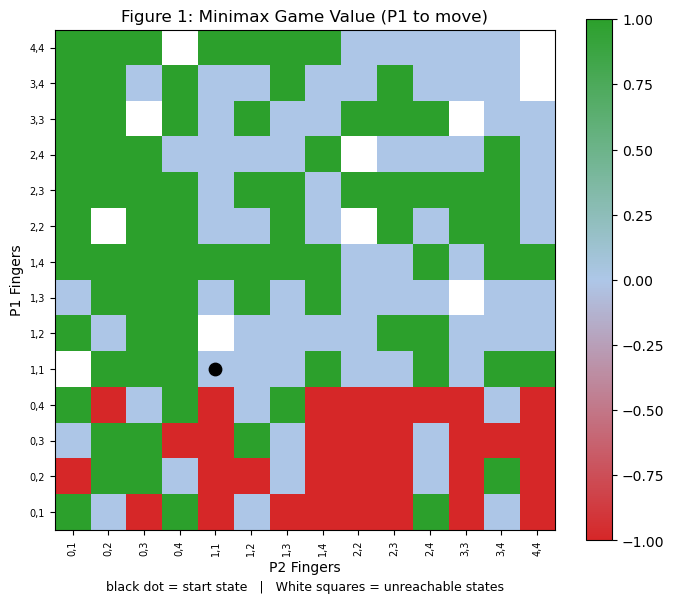

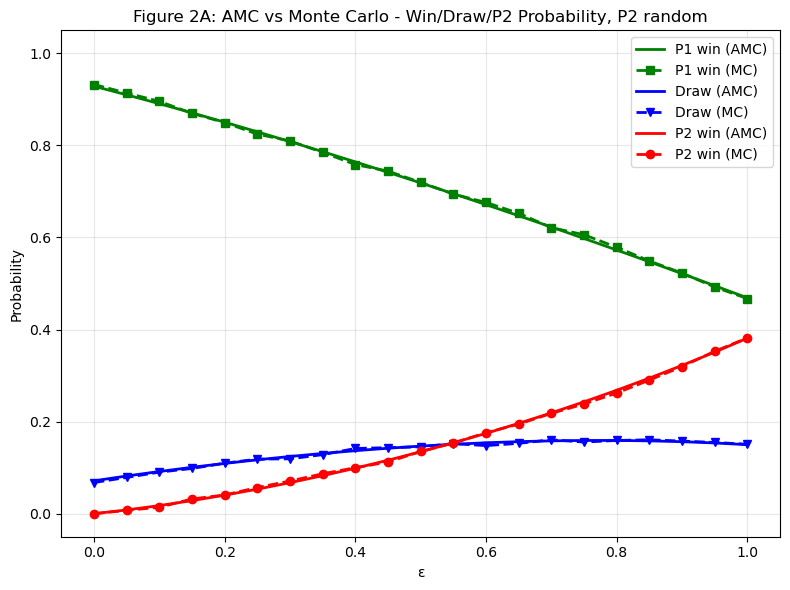

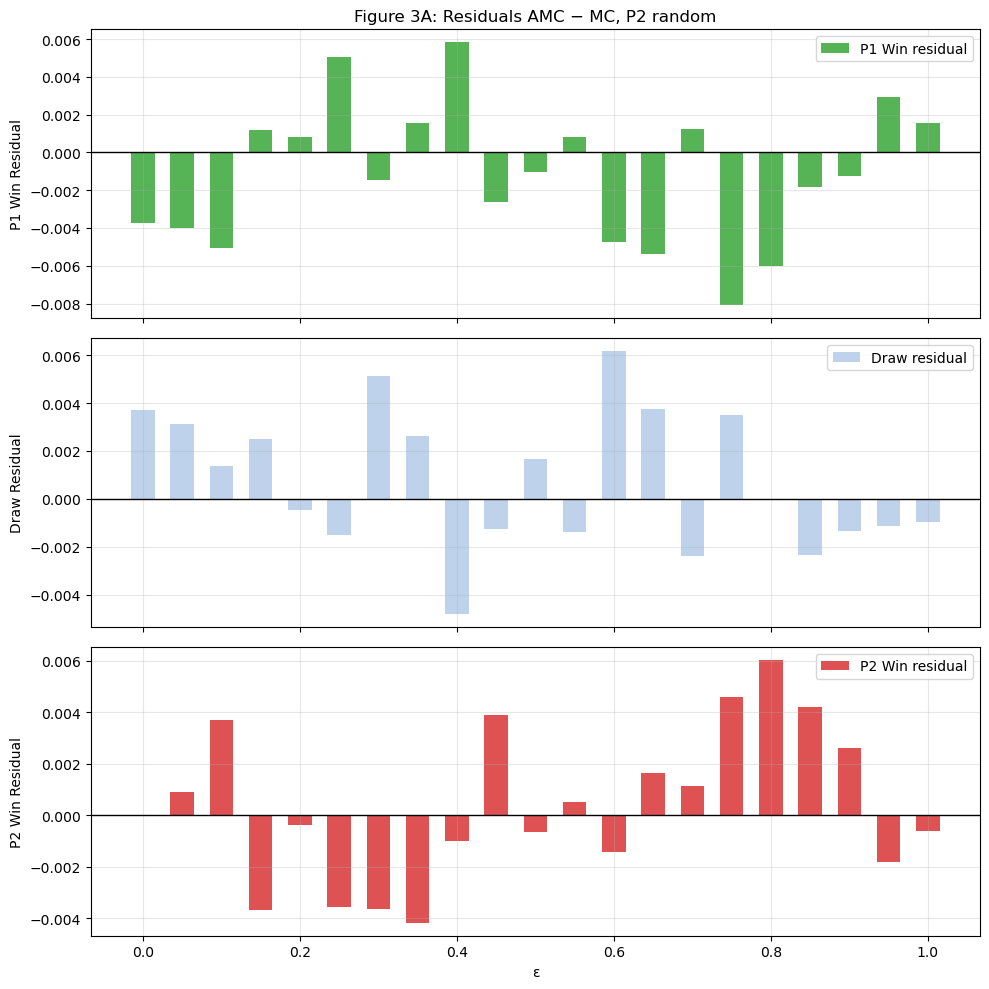

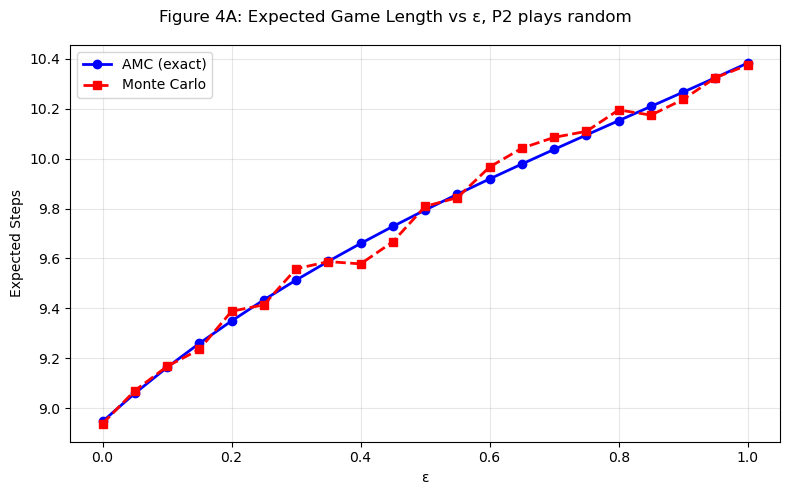

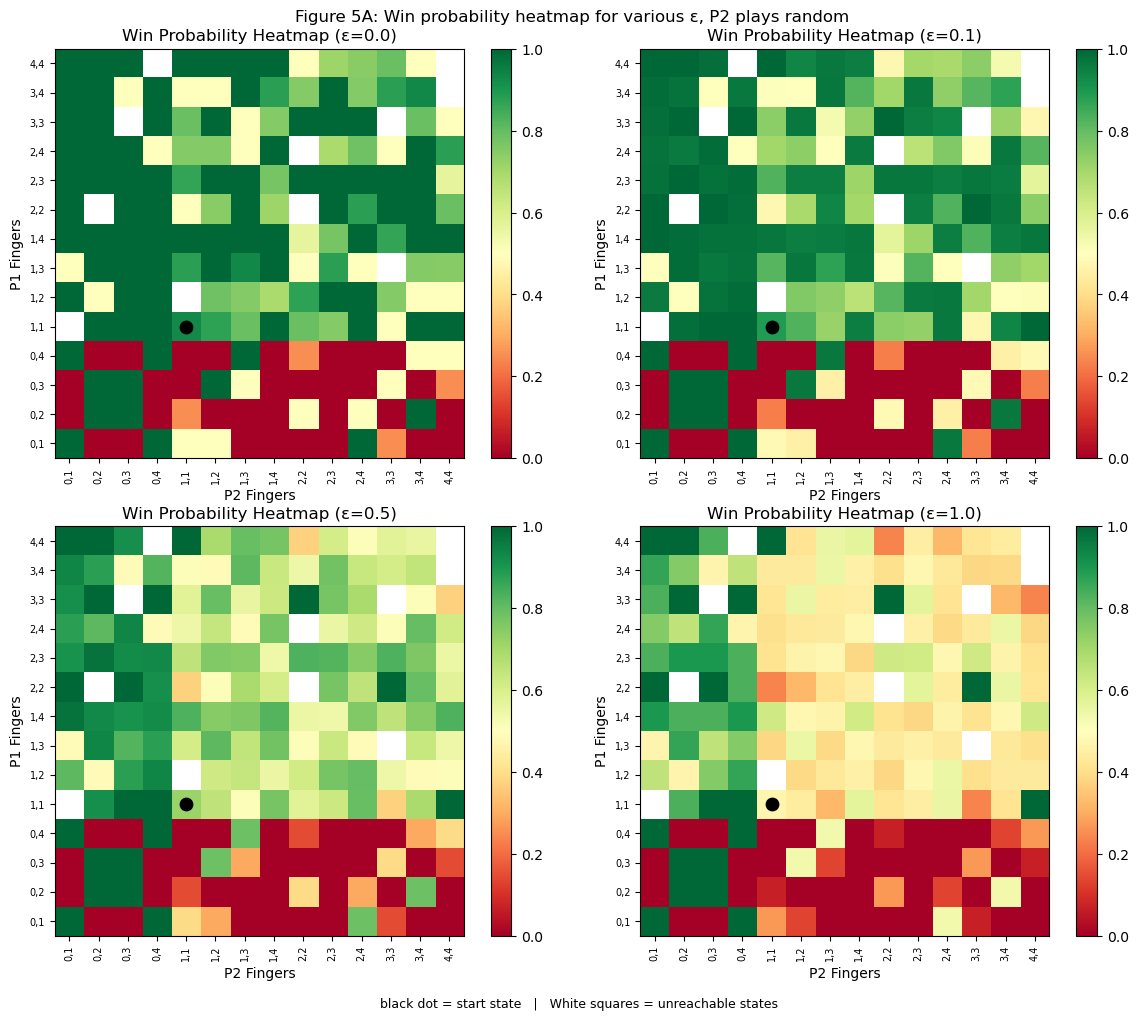

In [18]:
def rand_to_str(val):
    if val == True:
        return "True"
    return "False"
hands = [(i, j) for i in range(5) for j in range(i, 5) if not (i == 0 and j == 0)]
hand_to_idx = {h: idx for idx, h in enumerate(hands)}


# FIGURE 1 — MINIMAX HEATMAP

fig1, ax = plt.subplots(figsize=(7, 6))
grid_mm = np.full((14, 14), np.nan)

for state, val in values.items():
    a1, a2, b1, b2, turn = state
    if turn == 1:
        p1 = tuple(sorted((a1, a2)))
        p2 = tuple(sorted((b1, b2)))
        if p1 == (0, 0) or p2 == (0, 0):
            continue
        i = hand_to_idx[p1]
        j = hand_to_idx[p2]
        grid_mm[i, j] = val
print("Number of P1 win states =",np.sum(grid_mm==1))
print("Number of P1 loss states =", np.sum(grid_mm==-1))
print("Number of draw states =", np.sum(grid_mm==-0))

cmap_rg = mcolors.LinearSegmentedColormap.from_list(
    'rg', ['#d62728', '#aec7e8', '#2ca02c']
)

im = ax.imshow(grid_mm, origin='lower', cmap=cmap_rg, vmin=-1, vmax=1)
labels = [f"{h[0]},{h[1]}" for h in hands]
ax.set_xticks(range(14))
ax.set_yticks(range(14))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_yticklabels(labels, fontsize=7)

ax.set_title("Figure 1: Minimax Game Value (P1 to move)")
ax.set_xlabel("P2 Fingers")
ax.set_ylabel("P1 Fingers")
ax.scatter([4], [4], color='black', s=80, zorder=5)
ax.text(
    0.5, -0.1,
    "black dot = start state   |   White squares = unreachable states",
    transform=ax.transAxes,
    ha='center', va='top', fontsize=9
)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("Fig1 Minimax_heatmap"+".png")
plt.show()




# FIGURE 2 — AMC vs MC WIN & DRAW PROBABILITY

fig2, ax = plt.subplots(figsize=(8, 6))

#Win
ax.plot(epsilons, amc_win, 'g-', lw=2, label='P1 win (AMC)')
ax.plot(epsilons, mc_win,  'g--', lw=2, marker='s', label='P1 win (MC)')

#Draw
ax.plot(epsilons, amc_draw, 'b-', lw=2, label='Draw (AMC)')
ax.plot(epsilons, mc_draw,  'b--', lw=2, marker='v', label='Draw (MC)')

#Loss
ax.plot(epsilons, amc_p2, 'r-', lw=2, label='P2 win (AMC)')
ax.plot(epsilons, mc_p2,  'r--', lw=2, marker='o', label='P2 win (MC)')
if P2_Random:
    ax.set_title("Figure 2A: AMC vs Monte Carlo - Win/Draw/P2 Probability, P2 random")
else:
    ax.set_title("Figure 2B: AMC vs Monte Carlo - Win/Draw/P2 Probability, P2 ε-greedy")
ax.set_xlabel("ε")
ax.set_ylabel("Probability")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig("Fig2_Win_draw_p2win_probability_random_"+rand_to_str(P2_Random)+".png")
plt.show()


# FIGURE C — Residuals (Win on top, Draw on bottom)

fig3, (ax_win, ax_draw, ax_p2) = plt.subplots(
    3, 1, figsize=(10, 10), sharex=True
)

width = 0.03

# --- WIN residuals ---
ax_win.bar(
    epsilons,
    amc_win - mc_win,
    width=width,
    color='#2ca02c',
    alpha=0.8,
    label='P1 Win residual'
)
ax_win.axhline(0, color='black', lw=1)
ax_win.set_ylabel("P1 Win Residual")
if P2_Random:
    ax_win.set_title("Figure 3A: Residuals AMC − MC, P2 random")
else:
    ax_win.set_title("Figure 3B: Residuals AMC − MC, P2 ε-greedy")
ax_win.grid(True, alpha=0.3)
ax_win.legend()

# --- DRAW residuals ---
ax_draw.bar(
    epsilons,
    amc_draw - mc_draw,
    width=width,
    color='#aec7e8',
    alpha=0.8,
    label='Draw residual'
)
ax_draw.axhline(0, color='black', lw=1)
ax_draw.set_ylabel("Draw Residual")
ax_draw.grid(True, alpha=0.3)
ax_draw.legend()
ax_p2.bar(
    epsilons,
    amc_p2 - mc_p2,
    width=width,
    color='#d62728',
    alpha=0.8,
    label='P2 Win residual'
)
ax_p2.axhline(0, color='black', lw=1)
ax_p2.set_xlabel("ε")
ax_p2.set_ylabel("P2 Win Residual")
ax_p2.grid(True, alpha=0.3)
ax_p2.legend()

plt.tight_layout()
plt.savefig("Fig3_Win_draw_p2_residuals_random_"+rand_to_str(P2_Random)+".png")
plt.show()




# FIGURE D — EXPECTED GAME LENGTH

figD, ax = plt.subplots(figsize=(8, 5))

ax.plot(epsilons, amc_len, 'b-', lw=2, marker='o', label='AMC (exact)')
ax.plot(epsilons, mc_len,  'r--', lw=2, marker='s', label='Monte Carlo')

if P2_Random:
    figD.suptitle("Figure 4A: Expected Game Length vs ε, P2 plays random")
else:
    figD.suptitle("Figure 4B: Expected Game Length vs ε, P2 plays ε-greedy")

ax.set_xlabel("ε")
ax.set_ylabel("Expected Steps")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("Fig4_Expected_game_length_random_"+rand_to_str(P2_Random)+".png")
plt.show()



# FIGURE E — HEATMAPS (2×2 GRID)

figE, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, eps in enumerate(eps_samples):
    ax = axes[idx]
    grid_wp = np.full((14, 14), np.nan)

    for state, wp in heatmap_data[eps].items():
        a1, a2, b1, b2, turn = state
        if turn == 1:
            p1 = tuple(sorted((a1, a2)))
            p2 = tuple(sorted((b1, b2)))
            if p1 == (0, 0) or p2 == (0, 0):
                continue
            i = hand_to_idx[p1]
            j = hand_to_idx[p2]
            grid_wp[i, j] = wp

    im = ax.imshow(grid_wp, origin='lower', cmap='RdYlGn', vmin=0, vmax=1)
    labels = [f"{h[0]},{h[1]}" for h in hands]
    ax.set_xticks(range(14))
    ax.set_yticks(range(14))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticklabels(labels, fontsize=7)
    ax.set_title(f"Win Probability Heatmap (ε={eps})")
    ax.set_xlabel("P2 Fingers")
    ax.set_ylabel("P1 Fingers")
    figE.colorbar(im, ax=ax)
    ax.scatter([4], [4], color='black', s=80, zorder=5)
figE.text(
    -0.15, -0.15,
    "black dot = start state   |   White squares = unreachable states",
    transform=ax.transAxes,
    ha='center', va='top', fontsize=9
)
if P2_Random:
    figE.suptitle("Figure 5A: Win probability heatmap for various ε, P2 plays random")
else:
    figE.suptitle("Figure 5B: Win probability heatmap for various ε, P2 plays ε-greedy")
plt.tight_layout()
plt.savefig("Fig5_win_probability_heatmap_random_"+rand_to_str(P2_Random)+".png")
plt.show()
